- Github repository: https://github.com/Simen03/simen03-ind320-app 
- Streamlit app: https://simen03-ind320-app-hkg3slagiyz8dtmwljxdtd.streamlit.app/
- Link to video: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=341f3e25-d0d5-4c22-b7bc-b4e9012f4831

### AI usage

### Log

### Imports

In [2]:
import geopandas as gpd
import pandas as pd
import numpy as np
import openmeteo_requests, requests_cache
from retry_requests import retry
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram

import sys
sys.path.append("..")   # so the notebook can import from modules/
from modules.NVE_API import areas, fetch_reservoirs, select_area

In [3]:
# Read the shapefiles downloaded from atlas.nve.no
vass = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding="utf-8")      # file names will differ
el = gpd.read_file("../data/Budområder/Budområder.shp", encoding="utf-8")

#print(el.crs, el.columns)    # check the coordinate system and which column holds the area name

In [4]:
# NVE regions -> Magasinstatistikk VASS areas.
vass_map = {
    "RS": "VASS 1", "RØ": "VASS 1",   # Sørøst-Norge / Østlandet
    "RV": "VASS 2",                   # Vest-Norge
    "RM": "VASS 3", "RN": "VASS 3",   # Midt- and Nord-Norge
}
vass["region_id"] = vass["REGION"].map(vass_map)

# Sanity check: every region must get a VASS id (NaN here usually means Ø was read with the wrong encoding)
print(vass[["REGION", "REGIONNAVN", "region_id"]])
assert vass["region_id"].notna().all()

# Merge the polygons: 5 NVE regions -> 3 VASS areas
vass = vass[["region_id", "geometry"]].dissolve(by="region_id").reset_index()
print(vass)

  REGION         REGIONNAVN region_id
0     RV        Region Vest    VASS 2
1     RM  Region Midt-Norge    VASS 3
2     RN        Region Nord    VASS 3
3     RØ         Region Øst    VASS 1
4     RS         Region Sør    VASS 1
  region_id                                           geometry
0    VASS 1  POLYGON ((244204.94 6521981.68, 231754.99 6523...
1    VASS 2  POLYGON ((193105.76 6929797.839, 191705.75 692...
2    VASS 3  POLYGON ((522969.98 7381455.32, 520050.96 7378...


In [5]:
# Price areas: "NO 1" -> "NO1", to match the labels used in the app
el["region_id"] = el["budomr"].str.replace(" ", "")
el = el[["region_id", "geometry"]]

In [6]:
regions = pd.concat([el[["region_id", "geometry"]], vass[["region_id", "geometry"]]])
regions = gpd.GeoDataFrame(regions, crs=el.crs)

# sample_points (geopandas >= 1.0) returns one MultiPoint per polygon -> explode to single points
pts = regions.set_index("region_id").sample_points(size=1000, rng=42)   # rng makes it reproducible
pts = pts.explode().to_crs(epsg=4326)

coords = pd.DataFrame({"region_id": pts.index,
                       "lon": pts.x.values,
                       "lat": pts.y.values})
coords.to_csv("../data/region_coords.csv", index=False)   # the app will reuse this file

In [7]:
# Cached + retrying session, as generated on open-meteo.com
session = retry(requests_cache.CachedSession(".cache", expire_after=-1), retries=5, backoff_factor=0.2)
om = openmeteo_requests.Client(session=session)

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARS = ["temperature_2m", "precipitation", "wind_speed_10m", "relative_humidity_2m"]

def download_weather(region_id, start, end, n_locations=10, coords_file="../data/region_coords.csv"):
    """Download hourly ERA5 data for a region and return the hourly average over the sampled locations."""
    coords = pd.read_csv(coords_file)
    c = coords[coords["region_id"] == region_id]
    # ERA5 grid is ~0.25 deg: round and drop duplicates so we don't download the same cell twice
    c = c.assign(lat=c.lat.round(2), lon=c.lon.round(2)).drop_duplicates(["lat", "lon"])
    c = c.sample(min(n_locations, len(c)), random_state=1)

    params = {
        "latitude": c["lat"].tolist(),        # several locations in one request
        "longitude": c["lon"].tolist(),
        "start_date": str(start), "end_date": str(end),
        "hourly": HOURLY_VARS,
        "models": "era5",
        "timezone": "Europe/Oslo",
    }
    responses = om.weather_api(ARCHIVE_URL, params=params)   # one response per location

    frames = []
    for r in responses:
        h = r.Hourly()
        time = pd.date_range(start=pd.to_datetime(h.Time(), unit="s", utc=True),
                             end=pd.to_datetime(h.TimeEnd(), unit="s", utc=True),
                             freq=pd.Timedelta(seconds=h.Interval()), inclusive="left")
        frames.append(pd.DataFrame({v: h.Variables(i).ValuesAsNumpy() for i, v in enumerate(HOURLY_VARS)},
                                   index=time))
    # Average across locations, hour by hour
    return pd.concat(frames).groupby(level=0).mean()

weather = download_weather("NO3", "2024-01-01", "2024-12-31")

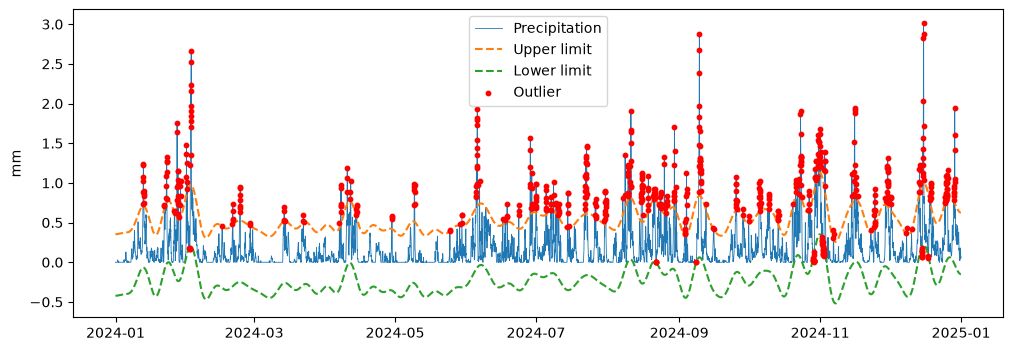

In [8]:
def spc_outliers(series, cutoff=0.01, n_std=3.0):
    """SPC outlier detection on DCT high-pass filtered data (SATV).
    cutoff: fraction of DCT coefficients treated as low-frequency (seasonal) and removed.
    n_std: number of robust standard deviations for the control limits."""
    x = series.to_numpy()
    coefs = dct(x, norm="ortho")
    k = int(cutoff * len(coefs))                 # number of low-frequency coefficients to remove

    low = coefs.copy(); low[k:] = 0              # keep only the slow/seasonal part
    trend = idct(low, norm="ortho")
    satv = x - trend                             # high-pass = original - low-pass

    med = np.median(satv)
    sigma = median_abs_deviation(satv, scale="normal")   # robust estimate of std
    upper = trend + med + n_std * sigma          # boundaries shown on the ORIGINAL scale
    lower = trend + med - n_std * sigma
    is_out = (satv > med + n_std * sigma) | (satv < med - n_std * sigma)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, x, lw=0.6, label="Precipitation")
    ax.plot(series.index, upper, "--", label="Upper limit")
    ax.plot(series.index, lower, "--", label="Lower limit")
    ax.scatter(series.index[is_out], x[is_out], color="red", s=10, zorder=3, label="Outlier")
    ax.legend(); ax.set_ylabel("mm")

    summary = {"n_outliers": int(is_out.sum()), "share": float(is_out.mean()),
               "median_satv": med, "robust_std": sigma}
    outliers = series[is_out].to_frame("precipitation")
    return fig, summary, outliers

fig, summary, out = spc_outliers(weather["precipitation"])

In [9]:
def lof_anomalies(series, contamination=0.01, n_neighbors=20):
    """Temperature anomalies using Local Outlier Factor. contamination = expected share of outliers."""
    t = np.arange(len(series))                                      # time as a feature
    X = StandardScaler().fit_transform(np.column_stack([t, series.to_numpy()]))
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_out = lof.fit_predict(X) == -1                               # -1 = outlier

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, series, lw=0.6, label="Temperature")
    ax.scatter(series.index[is_out], series[is_out], color="red", s=10, zorder=3, label="Anomaly")
    ax.legend(); ax.set_ylabel("°C")

    summary = {"n_anomalies": int(is_out.sum()), "share": float(is_out.mean()),
               "min": float(series[is_out].min()), "max": float(series[is_out].max())}
    return fig, summary, series[is_out].to_frame("temperature")

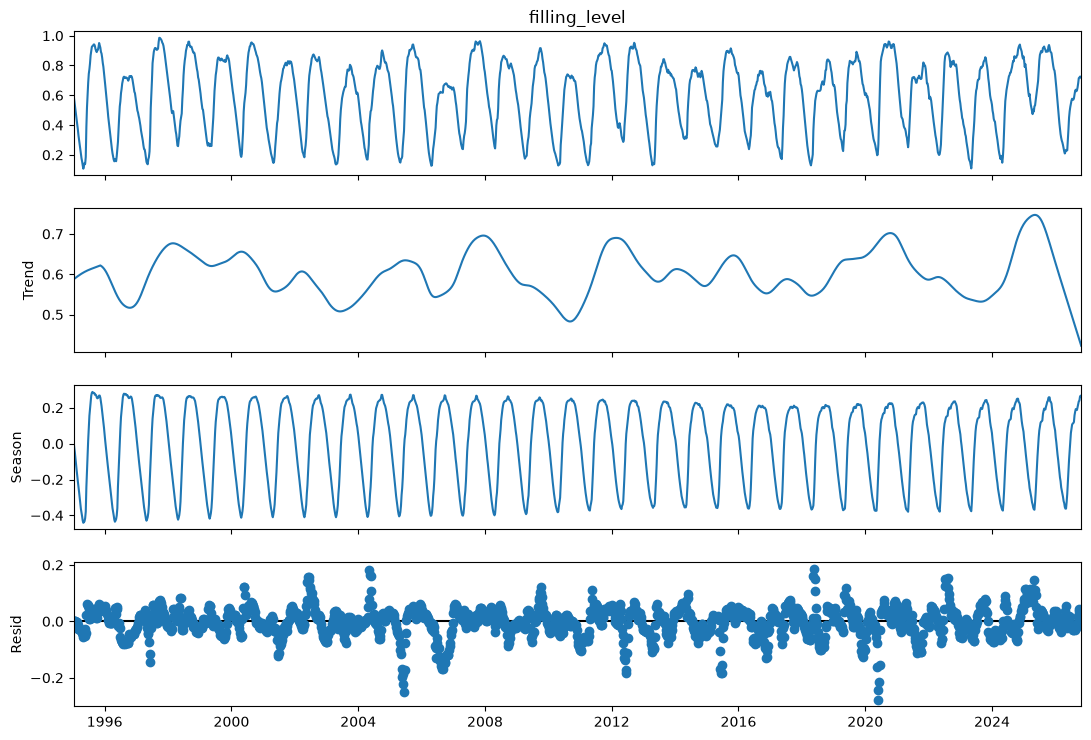

In [10]:
def stl_plot(series, period=52, seasonal=13, trend=89, robust=True):
    """STL decomposition of weekly filling level. seasonal and trend must be odd integers."""
    s = series.asfreq("W-SUN").interpolate()
    res = STL(s, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()
    fig = res.plot()
    fig.set_size_inches(12, 8)
    plt.close(fig)        
    return fig

df = fetch_reservoirs()
fill = select_area(df, "EL", 3)["filling_level"]
stl_plot(fill)

In [11]:
def spectrogram_plot(series, window_length=104, overlap=78):
    """Spectrogram of weekly data. window_length and overlap are in weeks."""
    s = series.asfreq("W-SUN").interpolate()
    f, t, Sxx = spectrogram(s.to_numpy(), fs=52,          # fs=52 -> frequency in cycles per year
                            nperseg=window_length, noverlap=overlap, detrend="linear")
    times = s.index[0] + pd.to_timedelta(t * 365.25, unit="D")   # convert to dates for the x-axis

    fig, ax = plt.subplots(figsize=(12, 4))
    m = ax.pcolormesh(times, f, 10 * np.log10(Sxx + 1e-12), shading="auto")
    fig.colorbar(m, ax=ax, label="Power (dB)")
    ax.set_ylabel("Cycles per year"); ax.set_xlabel("Time")
    return fig